[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_3_Analisis_Exploratorio.ipynb)

# Fase 3. Análisis exploratorio de datos

Describo el conjunto de entrenamiento con cinco propiedades fisicoquímicas: peso molecular, MolLogP, donantes, aceptores y TPSA. La fase 2 calculó 217 descriptores escalares de RDKit; el CSV también incluye la variable derivada `LipinskiViolations`, por eso el resumen de variables numéricas muestra 218. Mantengo test reservado para evaluar los modelos.

## 3.1. Lectura de los datos

Leo los CSV preparados en la fase anterior desde la carpeta pública del proyecto. Así puedo ejecutar este notebook sin subir archivos manualmente.

In [1]:
%pip -q install rdkit


In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
dilist['nombre_normalizado'] = dilist['CompoundName'].astype('string').str.strip().str.casefold()  # Quito espacios laterales para evitar falsos no encontrados.
estructuras['nombre_normalizado'] = estructuras['CompoundName'].astype('string').str.strip().str.casefold()  # Creo la misma clave normalizada en el mapa.
datos = dilist.merge(estructuras.drop(columns='CompoundName'), on='nombre_normalizado', how='left')  # Uno por nombre normalizado sin perder la etiqueta original.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

He cargado los datos del repositorio: /content/datos_dili
Descriptores numéricos disponibles: 218


## 3.2. Resumen univariado

Para cada descriptor calculo media, mediana, moda, desviación estándar, mínimo, máximo y cuartiles. También cuento las etiquetas DILI en valores absolutos y relativos.

In [3]:
# Selecciono cinco propiedades fisicoquímicas fáciles de interpretar.
variables = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA']  # Escojo las variables de Lipinski y TPSA.
variables = [variable for variable in variables if variable in train_df.columns]  # Confirmo que estén en el conjunto.

# Calculo las medidas de resumen univariado con entrenamiento.
resumen = train_df[variables].describe().T  # Obtengo media, desviación, mínimo, cuartiles y máximo.
resumen['mediana'] = train_df[variables].median()  # Añado la mediana.
resumen['moda'] = train_df[variables].mode().iloc[0]  # Añado la moda más frecuente.
display(resumen.round(2))  # Muestro el resumen redondeado.
print('Lectura de las medidas:')  # Inicio el comentario de los resultados calculados.
for variable in variables:  # Recorro las propiedades estudiadas.
    print(f"{variable}: mediana {resumen.loc[variable, 'mediana']:.2f}; la mitad central está entre {resumen.loc[variable, '25%']:.2f} y {resumen.loc[variable, '75%']:.2f}.")  # Interpreto centro y dispersión observados.

# Cuento las clases DILI en frecuencia absoluta y relativa.
frecuencias = train_df['DILI'].value_counts().sort_index().to_frame('frecuencia')  # Cuento registros por clase.
frecuencias['porcentaje'] = (100 * frecuencias['frecuencia'] / len(train_df)).round(1)  # Calculo porcentajes.
frecuencias.index = frecuencias.index.map({0: 'DILI negativa', 1: 'DILI positiva'})  # Pongo nombres legibles.
display(frecuencias)  # Muestro la distribución de clases.
print(f"En train, {frecuencias.loc['DILI positiva', 'porcentaje']:.1f}% tiene etiqueta positiva y {frecuencias.loc['DILI negativa', 'porcentaje']:.1f}% negativa.")  # Comento el balance observado.


,count,mean,std,min,25%,50%,75%,max,mediana,moda
MolWt,947.0,414.58,463.20,18.02,257.33,329.37,429.56,7053.95,329.37,135.21
MolLogP,947.0,1.76,3.86,-49.12,0.70,2.36,3.70,9.91,2.36,-3.59
NumHDonors,947.0,2.89,6.89,0.00,1.00,2.00,3.00,100.00,2.00,1.00
NumHAcceptors,947.0,5.70,7.10,0.00,3.00,4.00,6.00,99.00,4.00,3.00
TPSA,947.0,110.85,200.33,0.00,45.24,74.60,115.17,2912.95,74.60,3.24


Lectura de las medidas:
MolWt: mediana 329.37; la mitad central está entre 257.33 y 429.56.
MolLogP: mediana 2.36; la mitad central está entre 0.70 y 3.70.
NumHDonors: mediana 2.00; la mitad central está entre 1.00 y 3.00.
NumHAcceptors: mediana 4.00; la mitad central está entre 3.00 y 6.00.
TPSA: mediana 74.60; la mitad central está entre 45.24 y 115.17.


,frecuencia,porcentaje
DILI,,
DILI negativa,365,38.5
DILI positiva,582,61.5


En train, 61.5% tiene etiqueta positiva y 38.5% negativa.


## 3.3 Análisis bivariante y relaciones entre descriptores

Las cajas y las medianas comparan cada propiedad fisicoquímica con la etiqueta DILI. Después se contrasta formalmente si las distribuciones de esas propiedades difieren entre las dos clases.

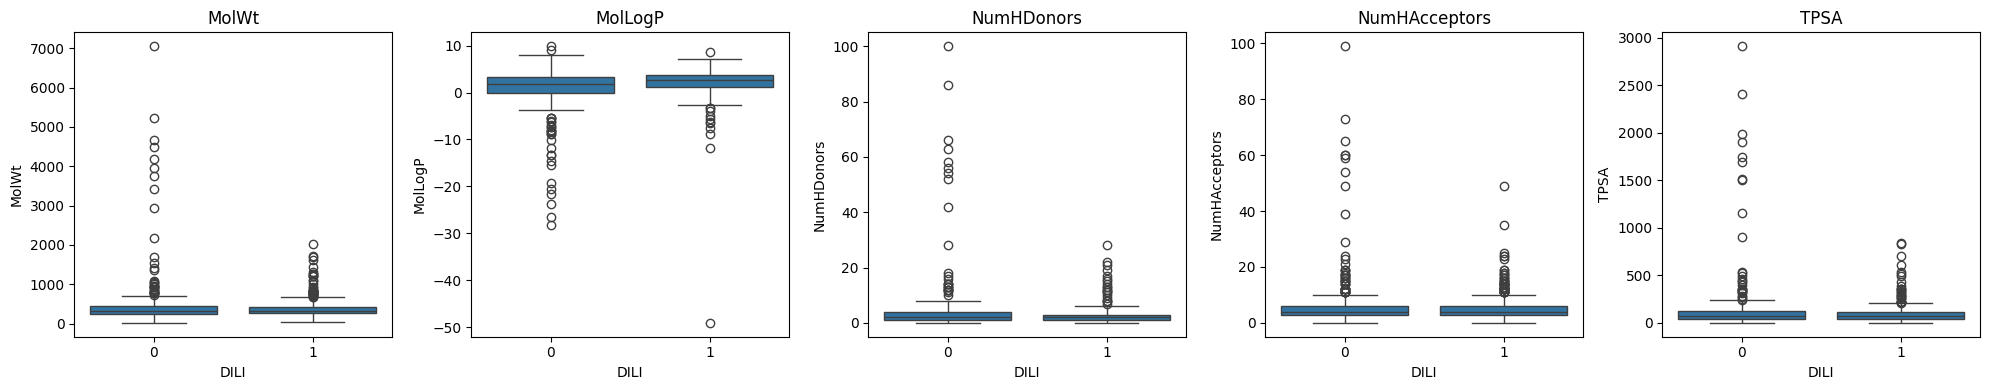

DILI,DILI negativa,DILI positiva,diferencia (positiva − negativa)
MolWt,324.38,331.98,7.60
MolLogP,1.86,2.62,0.77
NumHDonors,2.00,2.00,0.00
NumHAcceptors,4.00,4.00,0.00
TPSA,74.68,74.58,-0.10


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Comparo las cinco propiedades entre las clases DILI negativa y positiva.
fig, axes = plt.subplots(1, len(variables), figsize=(4 * len(variables), 4))  # Creo un panel por propiedad.
for ax, variable in zip(axes, variables):  # Recorro las propiedades seleccionadas.
    sns.boxplot(data=train_df, x='DILI', y=variable, ax=ax)  # Comparo su distribución por clase.
    ax.set_title(variable)  # Identifico cada panel.
    ax.set_xlabel('DILI')  # Aclaro la codificación de clases.
plt.tight_layout()  # Ajusto los espacios.
plt.show()  # Muestro la comparación bivariada.

# Comparo las medianas para acompañar la lectura de los diagramas.
medianas_clase = train_df.groupby('DILI')[variables].median().T  # Calculo una mediana por clase.
medianas_clase['diferencia (positiva − negativa)'] = medianas_clase[1] - medianas_clase[0]  # Calculo el cambio entre grupos.
medianas_clase = medianas_clase.rename(columns={0: 'DILI negativa', 1: 'DILI positiva'})  # Pongo nombres descriptivos.
display(medianas_clase.round(2))  # Muestro las medianas y su diferencia.


### Contraste inferencial entre las clases DILI

Se aplica una prueba bilateral de Mann–Whitney U a cada una de las cinco propiedades para comparar DILI positiva y negativa en entrenamiento (antes del filtro de valores extremos, igual que los boxplots). La prueba se elige porque las distribuciones son asimétricas y contienen extremos; las observaciones son compuestos únicos e independientes. Se informa la diferencia de medianas y delta de Cliff para describir dirección y magnitud, y se ajustan los cinco valores p mediante Holm. Los valores p se calculan solo con train; el conjunto test permanece reservado.

In [8]:
# Importo la prueba no paramétrica para dos grupos independientes.
from scipy.stats import mannwhitneyu  # Comparo rangos entre DILI negativa y positiva.

# Comparo cada propiedad en los 947 registros originales de entrenamiento, antes del filtro 1,5 × RIC.
resultados_test = []  # Guardo el resultado de cada contraste.
for variable in variables:  # Recorro MolWt, MolLogP, HBD, HBA y TPSA.
    grupo_negativo = train_df.loc[train_df['DILI'] == 0, variable].dropna()  # Extraigo DILI negativa.
    grupo_positivo = train_df.loc[train_df['DILI'] == 1, variable].dropna()  # Extraigo DILI positiva.
    u, p = mannwhitneyu(grupo_positivo, grupo_negativo, alternative='two-sided')  # Contrasto diferencias de distribución.
    delta = 2 * u / (len(grupo_positivo) * len(grupo_negativo)) - 1  # Estimo delta de Cliff con dirección positiva-negativa.
    resultados_test.append({  # Guardo tamaños, medianas, efecto y significación.
        'Propiedad': variable,
        'n negativa': len(grupo_negativo),
        'n positiva': len(grupo_positivo),
        'Mediana negativa': grupo_negativo.median(),
        'Mediana positiva': grupo_positivo.median(),
        'Diferencia de medianas (positiva − negativa)': grupo_positivo.median() - grupo_negativo.median(),
        'U de Mann–Whitney': u,
        'Delta de Cliff': delta,
        'p sin ajustar': p
    })

# Ajusto por las cinco comparaciones para limitar falsos positivos por pruebas múltiples.
tabla_tests = pd.DataFrame(resultados_test)  # Organizo los contrastes en una tabla.
p_valores = tabla_tests['p sin ajustar'].to_numpy()  # Extraigo los cinco valores p.
orden = np.argsort(p_valores)  # Ordeno los valores p de menor a mayor.
p_ordenados = p_valores[orden]  # Mantengo el orden para el ajuste Holm.
p_holm_ordenados = np.maximum.accumulate((len(p_valores) - np.arange(len(p_valores))) * p_ordenados)  # Aplico el ajuste paso a paso de Holm.
p_holm = np.empty_like(p_valores)  # Reservo el resultado en el orden original.
p_holm[orden] = np.clip(p_holm_ordenados, 0, 1)  # Devuelvo los valores ajustados a cada propiedad.
tabla_tests['p ajustado (Holm)'] = p_holm  # Añado la significación ajustada.
display(tabla_tests.round(4))  # Muestro resultados y tamaño del efecto.

# Comento la dirección y el resultado de cada contraste sin confundir significación con magnitud.
for _, fila in tabla_tests.iterrows():  # Recorro la tabla final.
    direccion = 'mayor' if fila['Delta de Cliff'] > 0 else 'menor'  # Indico qué clase tiende a tener rangos mayores.
    lectura = 'evidencia de diferencia' if fila['p ajustado (Holm)'] < 0.05 else 'sin evidencia suficiente de diferencia'  # Interpreto el p ajustado.
    p_ajustado = fila['p ajustado (Holm)']  # Recupero el valor p corregido.
    p_texto = '<0.0001' if p_ajustado < 0.0001 else f'{p_ajustado:.4f}'  # Evito presentar p pequeños como cero.
    print(f"{fila['Propiedad']}: valores generalmente {direccion} en DILI positiva; delta de Cliff = {fila['Delta de Cliff']:.3f}; {lectura} tras el ajuste Holm (p {p_texto}).")  # Relaciono inferencia y efecto.


,Propiedad,n negativa,n positiva,Mediana negativa,Mediana positiva,Diferencia de medianas (positiva − negativa),U de Mann–Whitney,Delta de Cliff,p sin ajustar,p ajustado (Holm)
0,MolWt,365,582,324.3800,331.9755,7.5955,106802.5,0.0055,0.8861,0.8861
1,MolLogP,365,582,1.8551,2.6214,0.7663,126845.5,0.1942,<0.0001,<0.0001
2,NumHDonors,365,582,2.0000,2.0000,<0.0001,97649.5,-0.0806,0.0325,0.1300
3,NumHAcceptors,365,582,4.0000,4.0000,<0.0001,100453.0,-0.0542,0.1559,0.4678
4,TPSA,365,582,74.6800,74.5850,-0.0950,102154.0,-0.0382,0.3216,0.6432


MolWt: valores generalmente mayor en DILI positiva; delta de Cliff = 0.006; sin evidencia suficiente de diferencia tras el ajuste Holm (p = 0.8861).
MolLogP: valores generalmente mayor en DILI positiva; delta de Cliff = 0.194; evidencia de diferencia tras el ajuste Holm (p <0.0001).
NumHDonors: valores generalmente menor en DILI positiva; delta de Cliff = -0.081; sin evidencia suficiente de diferencia tras el ajuste Holm (p = 0.1300).
NumHAcceptors: valores generalmente menor en DILI positiva; delta de Cliff = -0.054; sin evidencia suficiente de diferencia tras el ajuste Holm (p = 0.4678).
TPSA: valores generalmente menor en DILI positiva; delta de Cliff = -0.038; sin evidencia suficiente de diferencia tras el ajuste Holm (p = 0.6432).


La prueba evalúa si las distribuciones de rangos difieren entre las clases; no demuestra causalidad ni mide por sí sola la importancia toxicológica. Un valor p pequeño puede acompañar una diferencia de magnitud reducida, por lo que se interpreta junto con la diferencia de medianas y delta de Cliff.

### Correlaciones entre propiedades y asociación exploratoria con DILI

A continuación se describen las correlaciones de Spearman entre propiedades y la asociación de los descriptores con la etiqueta. Estos coeficientes son medidas de asociación; el contraste Mann–Whitney anterior aporta la comparación inferencial entre las dos clases para las cinco propiedades.

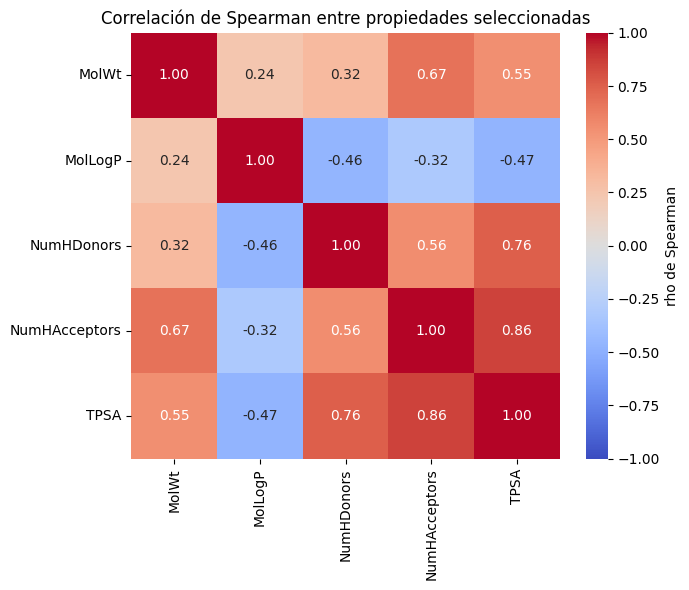

,descriptor,Spearman con DILI,n observaciones
0,FractionCSP3,-0.201484,947
1,BCUT2D_MRHI,0.181120,924
2,fr_Al_OH,-0.167608,947
3,BCUT2D_LOGPLOW,0.165538,924
4,MolLogP,0.163735,947
5,SlogP_VSA2,-0.159672,947
6,PEOE_VSA1,-0.148576,947
7,fr_quatN,-0.145857,947
8,SMR_VSA6,-0.141473,947
9,NumUnspecifiedAtomStereoCenters,-0.140836,947


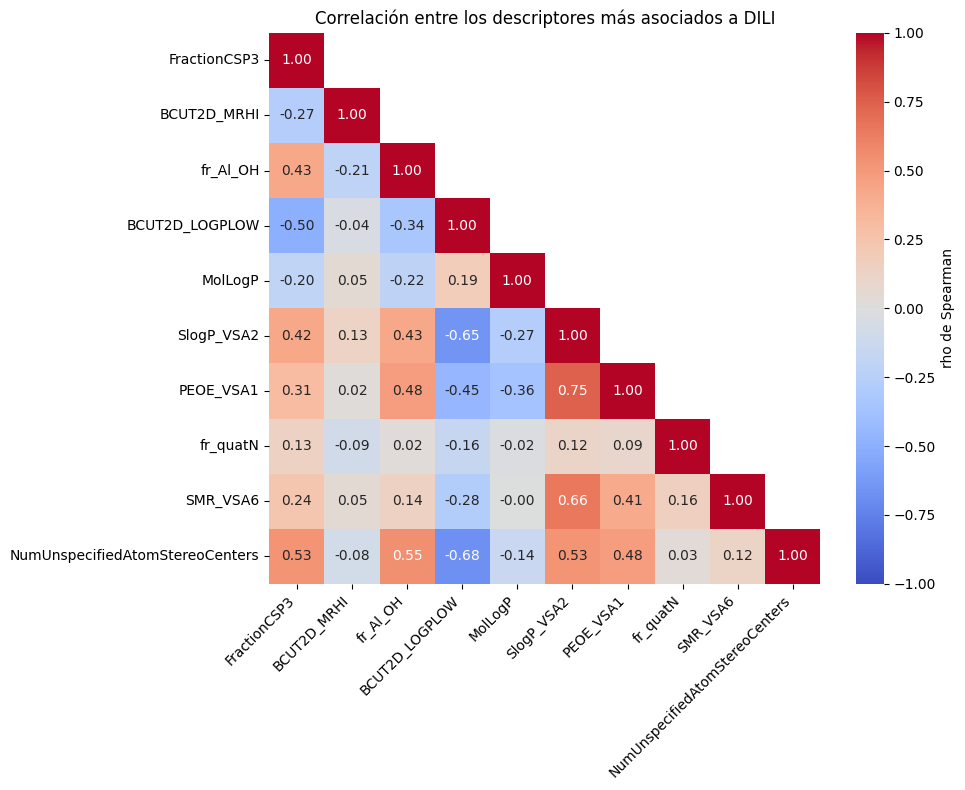

DILI,0,1,diferencia positiva-negativa
MolWt,324.38,331.98,7.60
MolLogP,1.86,2.62,0.77
TPSA,74.68,74.58,-0.10
NumHDonors,2.00,2.00,0.00
NumHAcceptors,4.00,4.00,0.00


,Spearman con DILI
MolLogP,0.163735
NumHDonors,-0.069520
NumHAcceptors,-0.046134
TPSA,-0.032231
MolWt,0.004663


Entre las cinco propiedades, MolLogP tiene la mayor asociación monotónica con DILI (rho = 0.16).
Las correlaciones describen asociaciones; no demuestran causalidad.


In [9]:
# Calculo la correlación entre las cinco propiedades fisicoquímicas del EDA.
correlaciones = train_df[variables].corr(method='spearman')  # Calculo Spearman con entrenamiento.
fig, ax = plt.subplots(figsize=(7, 6))  # Creo una figura independiente para esta matriz.
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, cbar_kws={'label': 'rho de Spearman'}, ax=ax)  # Represento una sola barra de color.
ax.set_title('Correlación de Spearman entre propiedades seleccionadas')  # Titulo el mapa.
plt.tight_layout()  # Ajusto la figura.
plt.show()  # Muestro la matriz.

# Reviso la asociación de los descriptores con DILI y retiro columnas con demasiados valores ausentes.
variables_amplias = [variable for variable in DESCRIPTORES if variable not in ['DILI', 'DILIST_ID'] and train_df[variable].notna().mean() >= 0.80 and train_df[variable].nunique(dropna=True) > 1]  # Filtro propiedades con suficientes observaciones.
correlacion_dili = train_df[variables_amplias + ['DILI']].corr(method='spearman', min_periods=100)['DILI'].drop('DILI').dropna()  # Calculo asociación con al menos cien pares.
top_asociaciones = correlacion_dili.abs().sort_values(ascending=False).head(15)  # Selecciono las quince asociaciones mayores.
resumen_asociaciones = pd.DataFrame({'descriptor': top_asociaciones.index, 'Spearman con DILI': correlacion_dili.loc[top_asociaciones.index].values, 'n observaciones': train_df[top_asociaciones.index].notna().sum().values})  # Añado el tamaño de cada comparación.
display(resumen_asociaciones)  # Muestro las asociaciones y sus tamaños.

# Represento la correlación entre los diez descriptores con mayor asociación a DILI.
top_diez = top_asociaciones.head(10).index.tolist()  # Selecciono diez variables para la matriz.
matriz_amplia = train_df[top_diez].corr(method='spearman', min_periods=100)  # Calculo correlaciones con al menos cien observaciones comunes.
fig, ax = plt.subplots(figsize=(10, 8))  # Creo una segunda figura independiente.
mascara = np.triu(np.ones_like(matriz_amplia, dtype=bool), k=1)  # Oculto la mitad superior repetida.
sns.heatmap(matriz_amplia, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'label': 'rho de Spearman'}, ax=ax)  # Dibujo una matriz legible con una barra.
ax.set_title('Correlación entre los descriptores más asociados a DILI')  # Titulo la segunda matriz.
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')  # Giro los nombres para que no se solapen.
plt.tight_layout()  # Ajusto etiquetas y márgenes.
plt.show()  # Muestro la matriz amplia.

# Comparo las medianas de las cinco propiedades del EDA entre las clases DILI.
medianas = train_df.groupby('DILI')[variables].median().T  # Calculo medianas por clase.
medianas['diferencia positiva-negativa'] = medianas[1] - medianas[0]  # Calculo una diferencia descriptiva.
display(medianas.sort_values('diferencia positiva-negativa', key=abs, ascending=False).round(2))  # Ordeno por diferencia absoluta.

# Calculo la asociación de las cinco propiedades seleccionadas con DILI.
relacion = train_df[variables + ['DILI']].corr(method='spearman')['DILI'].drop('DILI')  # Extraigo la correlación con la etiqueta.
display(relacion.sort_values(key=abs, ascending=False).to_frame('Spearman con DILI'))  # Muestro las asociaciones seleccionadas.
variable_mayor = relacion.abs().idxmax()  # Localizo la asociación de mayor magnitud.
print(f"Entre las cinco propiedades, {variable_mayor} tiene la mayor asociación monotónica con DILI (rho = {relacion[variable_mayor]:.2f}).")  # Comento signo y magnitud observados.
print('Las correlaciones describen asociaciones; no demuestran causalidad.')  # Aclaro su alcance.


## 3.4 Calidad de los datos y valores atípicos

Reviso nulos, duplicados y posibles valores atípicos. Uso el criterio de 1,5 veces el rango intercuartílico (RIC) en MolWt, MolLogP, donantes, aceptores y TPSA. Calculo los límites con train y retiro de train y test cualquier compuesto que quede fuera en al menos una propiedad. Antes del filtro, muestro algunas estructuras para revisar qué tipo de compuestos identifica.

In [10]:
# Calculo los valores ausentes y los duplicados antes de filtrar.
calidad = pd.DataFrame({'nulos': datos_limpios.isna().sum(), 'porcentaje_nulos': (100 * datos_limpios.isna().mean()).round(1)})  # Resumo valores ausentes.
display(calidad.sort_values('porcentaje_nulos', ascending=False).head(12))  # Muestro primero las columnas con más nulos.
print('Nombres sin estructura inequívoca:', datos['InChIKey'].isna().sum())  # Informo cobertura de estructuras.
print('Nombres repetidos en DILIst:', dilist['CompoundName'].duplicated().sum())  # Cuento nombres repetidos.
print('InChIKey repetidas en train:', train_df['InChIKey'].duplicated().sum())  # Compruebo duplicados químicos.
print('Filas con etiquetas contradictorias:', len(datos_conflicto))  # Muestro posibles conflictos.

# Calculo límites de 1,5 × RIC solo con train.
q1 = train_df[variables].quantile(0.25)  # Calculo el primer cuartil.
q3 = train_df[variables].quantile(0.75)  # Calculo el tercer cuartil.
ric = q3 - q1  # Calculo el rango intercuartílico.
lim_inf = q1 - 1.5 * ric  # Defino límites inferiores.
lim_sup = q3 + 1.5 * ric  # Defino límites superiores.
fuera_train = train_df[variables].lt(lim_inf) | train_df[variables].gt(lim_sup)  # Marco extremos por variable en train.
fuera_test = test_df[variables].lt(lim_inf) | test_df[variables].gt(lim_sup)  # Aplico a test los mismos límites.
tabla_outliers = pd.DataFrame({'límite inferior': lim_inf, 'límite superior': lim_sup, 'train': fuera_train.sum(), 'test': fuera_test.sum()})  # Organizo umbrales y recuentos.
tabla_outliers['train (%)'] = (100 * tabla_outliers['train'] / len(train_df)).round(1)  # Calculo porcentaje en train.
tabla_outliers['test (%)'] = (100 * tabla_outliers['test'] / len(test_df)).round(1)  # Calculo porcentaje en test.
display(tabla_outliers.round(2))  # Muestro los resultados.
mask_outlier_train = fuera_train.any(axis=1)  # Marco compuestos fuera de rango en al menos una propiedad.
mask_outlier_test = fuera_test.any(axis=1)  # Aplico la misma regla a test.
print(f"Train: retiro {mask_outlier_train.sum()} de {len(train_df)} compuestos ({100 * mask_outlier_train.mean():.1f}%).")  # Cuantifico la retirada.
print(f"Test: retiro {mask_outlier_test.sum()} de {len(test_df)} compuestos ({100 * mask_outlier_test.mean():.1f}%).")  # Cuantifico la retirada.
print('Calculo los límites solo con train y los aplico sin recalcularlos a test.')  # Explico el control de las particiones.


,nulos,porcentaje_nulos
Routes_of_Administration,252,21.3
BCUT2D_MWLOW,31,2.6
BCUT2D_CHGHI,31,2.6
BCUT2D_CHGLO,31,2.6
BCUT2D_LOGPHI,31,2.6
BCUT2D_LOGPLOW,31,2.6
BCUT2D_MRHI,31,2.6
BCUT2D_MRLOW,31,2.6
BCUT2D_MWHI,31,2.6
MinPartialCharge,3,0.3


Nombres sin estructura inequívoca: 95
Nombres repetidos en DILIst: 0
InChIKey repetidas en train: 0
Filas con etiquetas contradictorias: 0


,límite inferior,límite superior,train,test,train (%),test (%)
MolWt,-1.01,687.90,69,24,7.3,10.1
MolLogP,-3.82,8.22,38,15,4.0,6.3
NumHDonors,-2.00,6.00,56,14,5.9,5.9
NumHAcceptors,-1.50,10.50,92,26,9.7,11.0
TPSA,-59.66,220.06,54,13,5.7,5.5


Train: retiro 115 de 947 compuestos (12.1%).
Test: retiro 36 de 237 compuestos (15.2%).
Calculo los límites solo con train y los aplico sin recalcularlos a test.


### Lectura de calidad y extremos

En la tabla molecular hay 1.184 registros. La vía de administración tiene 252 valores ausentes (21,3 %); ocho descriptores BCUT2D presentan 31 ausencias cada uno (2,6 %) y tres descriptores de carga parcial tienen tres cada uno (0,3 %). De los 1.279 nombres de DILIst, 95 no quedaron asociados a una estructura. No encontré nombres repetidos, InChIKey duplicadas en train ni etiquetas contradictorias.

Los límites calculados con train fueron: MolWt de −1,01 a 687,90; MolLogP de −3,82 a 8,22; donantes de −2 a 6; aceptores de −1,5 a 10,5; y TPSA de −59,66 a 220,06. Marco como extremo un compuesto que rebasa al menos uno de esos límites. El filtro retira 115 de 947 observaciones de train (12,1 %) y 36 de 237 de test (15,2 %). El ejemplo mostrado, fondaparinux sodium, rebasa los cinco límites. Un valor extremo no demuestra por sí solo que el registro sea erróneo; aquí se excluye porque el análisis posterior se definió para el intervalo restante.

,CompoundName,DILI,MolWt,MolLogP,NumHDonors,NumHAcceptors,TPSA,criterio
558,fondaparinux sodium,1,1728.09,-49.12,9.0,49.0,833.78,"MolWt, MolLogP, NumHDonors, NumHAcceptors, TPSA"


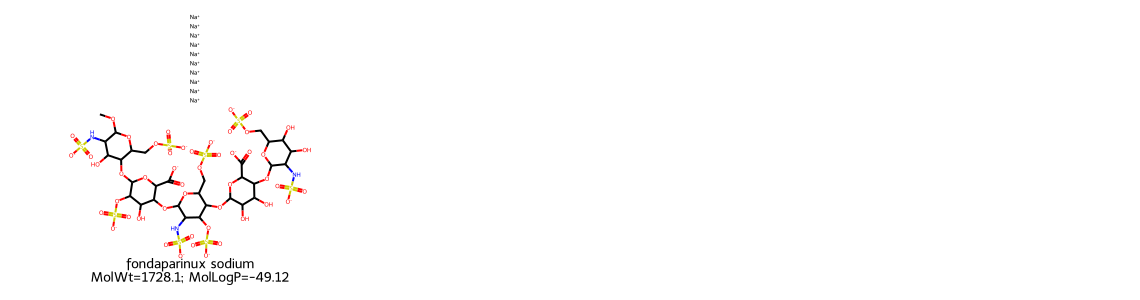

La figura permite revisar visualmente los compuestos que excluiré de los análisis posteriores.


In [11]:
# Selecciono tres compuestos de train marcados por el filtro.
compuestos_atipicos = train_df.loc[mask_outlier_train].copy()  # Reúno las filas que se retirarán.
nombres_ejemplo = ['atazanavir', 'montelukast', 'fondaparinux sodium']  # Elijo perfiles moleculares distintos.
ejemplos_atipicos = compuestos_atipicos[compuestos_atipicos['CompoundName'].str.casefold().isin(nombres_ejemplo)].copy()  # Localizo los ejemplos.
ejemplos_atipicos['criterio'] = ejemplos_atipicos.apply(lambda fila: ', '.join([v for v in variables if fuera_train.loc[fila.name, v]]), axis=1)  # Indico qué propiedad excede el límite.
columnas_ejemplo = ['CompoundName', 'DILI', 'MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA', 'criterio']  # Selecciono los datos a mostrar.
display(ejemplos_atipicos[columnas_ejemplo].round(2))  # Muestro sus valores.

# Dibujo las estructuras junto al nombre, peso molecular y MolLogP.
from rdkit import Chem  # Leo moléculas desde SMILES.
from rdkit.Chem import Draw  # Dibujo las estructuras químicas.
moleculas = []  # Guardo estructuras válidas.
leyendas = []  # Guardo las etiquetas de cada dibujo.
for _, fila in ejemplos_atipicos.iterrows():  # Recorro los compuestos escogidos.
    mol = Chem.MolFromSmiles(fila['SMILES'])  # Construyo una molécula desde SMILES.
    if mol is not None:  # Compruebo que RDKit la reconoce.
        moleculas.append(mol)  # Añado la estructura.
        leyendas.append(f"{fila['CompoundName']}\nMolWt={fila['MolWt']:.1f}; MolLogP={fila['MolLogP']:.2f}")  # Identifico el dibujo.
if moleculas:  # Compruebo que haya estructuras válidas.
    display(Draw.MolsToGridImage(moleculas, molsPerRow=3, subImgSize=(380, 300), legends=leyendas))  # Muestro las tres juntas.
print('La figura permite revisar visualmente los compuestos que excluiré de los análisis posteriores.')  # Interpreto los ejemplos.


In [12]:
# Resumo el balance de etiquetas antes del filtro.
proporciones = train_df['DILI'].value_counts(normalize=True)  # Calculo proporciones originales.
print(f"Antes del filtro, DILI positiva representa {100 * proporciones.get(1, 0):.1f}% y DILI negativa {100 * proporciones.get(0, 0):.1f}% de train.")  # Explico el balance.

# Comparo las medianas originales de MolLogP por clase.
medianas_logp = train_df.groupby('DILI')['MolLogP'].median()  # Calculo una mediana por clase.
print(f"Antes del filtro, la mediana de MolLogP es {medianas_logp.get(1, np.nan):.2f} en DILI positiva y {medianas_logp.get(0, np.nan):.2f} en DILI negativa.")  # Comparo ambas clases.

# Resumo la asociación y el tamaño que queda para las fases siguientes.
variable_mayor = relacion.abs().idxmax()  # Localizo la asociación absoluta más alta.
print(f"La mayor asociación entre las cinco propiedades es {variable_mayor} (rho = {relacion[variable_mayor]:.2f}).")  # Comento el resultado.
print(f"Tras el filtro quedan {len(train_df) - mask_outlier_train.sum()} compuestos en train y {len(test_df) - mask_outlier_test.sum()} en test.")  # Informo el tamaño posterior.
print('Estas relaciones son asociaciones y no permiten concluir causalidad.')  # Delimito el alcance.


Antes del filtro, DILI positiva representa 61.5% y DILI negativa 38.5% de train.
Antes del filtro, la mediana de MolLogP es 2.62 en DILI positiva y 1.86 en DILI negativa.
La mayor asociación entre las cinco propiedades es MolLogP (rho = 0.16).
Tras el filtro quedan 832 compuestos en train y 201 en test.
Estas relaciones son asociaciones y no permiten concluir causalidad.


## ¿Qué nos dicen los datos?

La comparación se realizó con los 947 compuestos de entrenamiento antes del filtro de valores extremos: 582 tenían clasificación DILI positiva y 365 negativa. Las medianas de MolWt fueron 331,98 Da en positivos y 324,38 Da en negativos; aunque la diferencia es de 7,60 Da, el delta de Cliff fue casi nulo (0,006; p ajustado de Holm = 0,886). Por tanto, no se encontró evidencia de una diferencia de distribución relevante en masa molecular.

La señal más clara apareció en MolLogP. La mediana fue 2,62 en positivos y 1,86 en negativos, con una diferencia de 0,77 unidades. El contraste de Mann–Whitney siguió siendo significativo tras corregir las cinco comparaciones (p de Holm < 0,0001), pero el delta de Cliff fue 0,194, lo que indica un efecto pequeño y una superposición considerable entre clases. Esto concuerda con la correlación de Spearman débil (ρ = 0,164): en este conjunto, la clase positiva tiende a ser algo más lipófila, pero MolLogP por sí solo no separa bien los compuestos.

Desde el punto de vista químico, una mayor lipofilia puede favorecer la partición hacia membranas y contribuir a la exposición hepática o al metabolismo del fármaco. Sin embargo, no demuestra que la lipofilia cause lesión hepática. La dosis, el metabolismo, el transporte, la solubilidad y la exposición también influyen; esos factores no están representados por esta comparación de descriptores.

Para las otras propiedades no se obtuvo evidencia de diferencias después del ajuste Holm: HBD (p = 0,130), HBA (p = 0,468) y TPSA (p = 0,643). Las medianas de donantes y aceptores fueron iguales entre clases, y la diferencia de TPSA fue mínima. Aunque el valor p sin ajustar de HBD fue 0,0325, dejó de ser significativo tras corregir las cinco pruebas. Por ello, no se interpreta como una diferencia confirmada. Entre los descriptores calculados, las asociaciones más altas con DILI también fueron modestas: FractionCSP3 (ρ = −0,201) y BCUT2D_MRHI (ρ = 0,181).

Las distribuciones presentan colas largas y valores extremos. El filtro de 1,5 × RIC, con límites calculados en train y aplicados sin recalcular a test, dejó 832 compuestos en train y 201 en test. Fondaparinux sodium fue el ejemplo visible que excedió los límites en las cinco propiedades; se trata de una estructura real y su exclusión delimita el espacio químico analizado, no indica que sea un dato erróneo.

La cobertura estructural también condiciona los resultados: no se obtuvo una estructura utilizable para 95 de los 1.279 nombres originales. Además, faltaba la vía de administración en 252 de las 1.184 estructuras (21,3 %), por lo que no se incorporó a los modelos. En conjunto, los análisis describen asociaciones entre estructura y etiqueta DILI en este conjunto de datos; no estiman directamente el riesgo clínico de un medicamento.